# Kenya RTFP market prices: CRISP-DM

This notebook studies the World Bank Kenya Monthly Food Price Estimates by Product and Market (RTFP). It is reproducible locally or in Colab. Set `DATA_PATH` to the supplied CSV location. Every numerical result below is computed from that file at execution time; no price observations are fabricated.

## 1. Business understanding

The business questions are: (1) which counties with recorded maize observations have similar mean-price and volatility profiles? (2) based on past county-month observations, is the trailing average currently rising, stable, or falling? (3) what linear trend rate describes each selected county's observed maize series? The last quantity is descriptive and is not a forecast or shopping recommendation.


In [1]:
from pathlib import Path
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, mean_squared_error,
                             precision_recall_fscore_support, r2_score, silhouette_score)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression

DATA_PATH = Path(os.environ.get(
    "RTFP_CSV", "../backend/data/rtfp_kenya_market_2007_2026-08.csv"
))
if not DATA_PATH.exists():
    raise FileNotFoundError("Set RTFP_CSV to the supplied RTFP CSV file.")

df = pd.read_csv(DATA_PATH)
df["price_date"] = pd.to_datetime(df["price_date"], errors="coerce")
print(f"Dataset file: {DATA_PATH.name}")
print(f"Rows: {len(df):,}; columns: {len(df.columns)}")


Dataset file: rtfp_kenya_market_2007_2026-08.csv
Rows: 55,224; columns: 46


## 2. Data understanding

The documented price columns are `beans` and `maize_fao` (KES/kg), and `livestock_goat_s_fao` (KES/unit). `inflation` and fields ending in `price_index` are index measures, not product prices. The source data contains market observations with sparse county/commodity coverage. The inspections below expose that coverage before modeling.


In [2]:
display(df.head())
display(df.tail())
df.info()
print("Shape:", df.shape)
display(df.describe(include="object").T)
display(df.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())

price_columns = ["beans", "maize_fao", "livestock_goat_s_fao"]
for column in price_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")
long_prices = df.melt(
    id_vars=["adm2_name", "mkt_name", "price_date"], value_vars=price_columns,
    var_name="commodity", value_name="price"
).dropna(subset=["price", "price_date"])
long_prices = long_prices[long_prices["mkt_name"].ne("Market Average")]
coverage = (long_prices.groupby(["adm2_name", "commodity"])
            .agg(observations=("price", "size"), first_date=("price_date", "min"),
                 last_date=("price_date", "max")).reset_index())
display(coverage.sort_values(["adm2_name", "commodity"]))
print("Counties with at least one price:", long_prices["adm2_name"].nunique())


,ISO3,country,adm1_name,adm2_name,mkt_name,lat,lon,geo_id,price_date,year,...,l_maize_fao,c_maize_fao,inflation_maize_fao,trust_maize_fao,o_food_price_index,h_food_price_index,l_food_price_index,c_food_price_index,inflation_food_price_index,trust_food_price_index
0,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-01-01,2007,...,21.29,22.23,NaN,9.7,0.50,0.52,0.47,0.50,NaN,9.0
1,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-02-01,2007,...,21.44,21.67,NaN,9.7,0.50,0.52,0.47,0.49,NaN,9.0
2,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-03-01,2007,...,19.51,19.51,NaN,9.7,0.48,0.51,0.46,0.49,NaN,9.0
3,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-04-01,2007,...,18.74,18.77,NaN,9.7,0.49,0.52,0.47,0.49,NaN,9.0
4,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-05-01,2007,...,16.90,16.90,NaN,9.7,0.48,0.51,0.46,0.46,NaN,9.0


,ISO3,country,adm1_name,adm2_name,mkt_name,lat,lon,geo_id,price_date,year,...,l_maize_fao,c_maize_fao,inflation_maize_fao,trust_maize_fao,o_food_price_index,h_food_price_index,l_food_price_index,c_food_price_index,inflation_food_price_index,trust_food_price_index
55219,KEN,Kenya,Market Average,Market Average,Market Average,NaN,NaN,gid_ken_national_average,2026-04-01,2026,...,85.58,88.44,-2.07,9.7,1.73,1.79,1.67,1.75,8.13,9.6
55220,KEN,Kenya,Market Average,Market Average,Market Average,NaN,NaN,gid_ken_national_average,2026-05-01,2026,...,86.78,87.15,-0.38,9.7,1.75,1.81,1.70,1.78,13.12,9.6
55221,KEN,Kenya,Market Average,Market Average,Market Average,NaN,NaN,gid_ken_national_average,2026-06-01,2026,...,85.32,87.46,-4.88,9.7,1.78,1.82,1.68,1.68,8.63,9.6
55222,KEN,Kenya,Market Average,Market Average,Market Average,NaN,NaN,gid_ken_national_average,2026-07-01,2026,...,85.96,87.42,-2.08,9.7,1.65,1.71,1.60,1.69,9.30,9.7
55223,KEN,Kenya,Market Average,Market Average,Market Average,NaN,NaN,gid_ken_national_average,2026-08-01,2026,...,85.76,87.94,-3.63,9.7,1.69,1.75,1.64,1.70,10.46,9.7


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55224 entries, 0 to 55223
Data columns (total 46 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   ISO3                            55224 non-null  object        
 1   country                         55224 non-null  object        
 2   adm1_name                       55224 non-null  object        
 3   adm2_name                       55224 non-null  object        
 4   mkt_name                        55224 non-null  object        
 5   lat                             54988 non-null  float64       
 6   lon                             54988 non-null  float64       
 7   geo_id                          55224 non-null  object        
 8   price_date                      55224 non-null  datetime64[ns]
 9   year                            55224 non-null  int64         
 10  month                           55224 non-null  int64         
 11  cu

,count,unique,top,freq
ISO3,55224,1,KEN,55224
country,55224,1,Kenya,55224
adm1_name,55224,16,Rift Valley,21948
adm2_name,55224,36,Turkana,13452
mkt_name,55224,234,Adele Center,236
geo_id,55224,234,gid_-4700000396100000,236
currency,55224,1,KES,55224
components,55224,1,"beans (1 KG, Index Weight = 1), livestock_goat...",55224
start_dense_data,55224,1,Jan 2007,55224
last_survey_point,55224,1,Aug 2026,55224


,missing_count
beans,53429
livestock_goat_s_fao,52671
maize_fao,52227
inflation_beans,2808
inflation_food_price_index,2808
inflation_maize_fao,2808
inflation_livestock_goat_s_fao,2808
lat,236
lon,236
mkt_name,0


,adm2_name,commodity,observations,first_date,last_date
0,Baringo,beans,77,2015-01-01,2022-02-01
1,Baringo,maize_fao,72,2015-01-01,2020-12-01
2,Chuka/Igambang'Ombe,livestock_goat_s_fao,159,2010-01-01,2026-05-01
3,Chuka/Igambang'Ombe,maize_fao,159,2010-01-01,2026-05-01
4,Garissa,beans,173,2018-12-01,2026-08-01
5,Garissa,livestock_goat_s_fao,162,2010-01-01,2026-05-01
6,Garissa,maize_fao,234,2010-01-01,2026-05-01
7,Hola (Tana River),maize_fao,72,2015-01-01,2020-12-01
8,Isiolo,beans,6,2021-02-01,2021-11-01
9,Isiolo,livestock_goat_s_fao,162,2010-01-01,2026-05-01


Counties with at least one price: 21


## 3. Data preparation

Missingness is not plausibly MCAR: which data are absent depends on county and commodity coverage and survey availability, so the pattern is at least MAR. Entirely unsurveyed county/commodity combinations (including Kisumu and Nakuru in this file) are also consistent with MNAR/coverage selection: they were not observed by this survey. We drop missing prices for the relevant task rather than impute unobserved markets or imply measured prices. This means all model results describe observed records only.

The IQR rule flags extreme observations for inspection. We report the count and retain flagged values: high and low food prices may be valid economic conditions, and automatic deletion would erase meaningful variation. MinMax scaling is applied to clustering and kNN features because those methods depend on distances. `clean_data.csv` is written under the ignored relative `notebooks/output/` directory.


In [3]:
q1 = long_prices.groupby("commodity")["price"].transform(lambda s: s.quantile(.25))
q3 = long_prices.groupby("commodity")["price"].transform(lambda s: s.quantile(.75))
iqr = q3 - q1
outlier_mask = (long_prices["price"] < q1 - 1.5 * iqr) | (long_prices["price"] > q3 + 1.5 * iqr)
print("IQR flagged rows retained:", int(outlier_mask.sum()), "of", len(long_prices))
clean_data = long_prices.copy()
clean_data["month"] = clean_data["price_date"].dt.to_period("M").dt.to_timestamp()
export_path = Path("output/clean_data.csv")
export_path.parent.mkdir(parents=True, exist_ok=True)
clean_data.to_csv(export_path, index=False)
print("Clean data export:", export_path.as_posix())


IQR flagged rows retained: 191 of 7345
Clean data export: output/clean_data.csv


## 4. Modelling

### 4a. Unsupervised county profiles: K-Means

We aggregate observed maize prices to county means and coefficients of variation (standard deviation divided by mean) to describe profile similarities without letting the price scale dominate volatility. This county aggregation is an analytical summary only; the API returns observed source-market records and does not average a county. K-Means minimizes squared Euclidean distance, so MinMax scaling is applied to mean price and coefficient of variation. Manhattan distance can be more robust to a single large coordinate difference, but vanilla K-Means optimizes Euclidean squared distance; for a Manhattan objective a medoid-based method would be a better fit. We compare the inertia elbow with silhouette scores and choose the elbow candidate when its silhouette is within 10% of the best score; otherwise we choose the best-silhouette candidate.


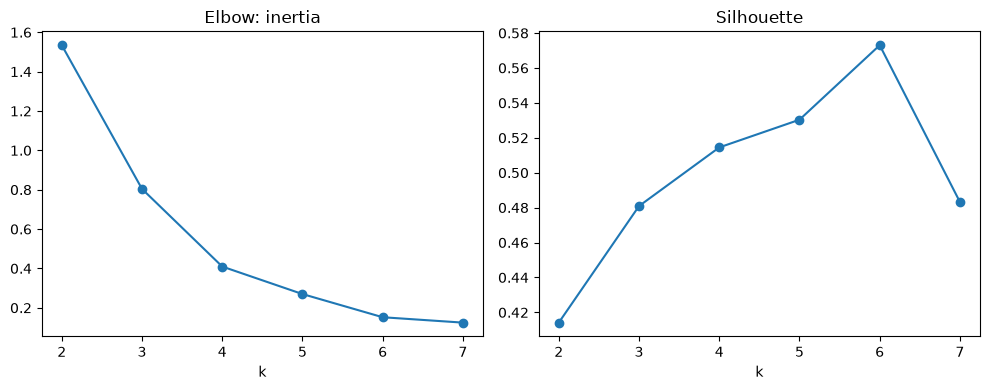

Elbow candidate k: 4
Best silhouette candidate k: 6
Selected k after elbow/silhouette comparison: 6
Silhouette at selected k: 0.573


,mean_price,price_std,observations,coefficient_of_variation,cluster
adm2_name,,,,,
Chuka/Igambang'Ombe,38.389937,14.500944,159,0.377728,0
Kitui,34.530303,13.374595,198,0.387329,0
Mbeere North,38.723270,14.982231,159,0.386905,0
Lamu West,39.836478,13.876432,159,0.348335,0
North Imenti,36.125786,14.516574,159,0.401834,0
Garissa,61.457265,12.929003,234,0.210374,1
Wajir,57.918239,14.200182,159,0.245176,1
Hola (Tana River),51.184028,10.240658,72,0.200075,2
Kajiado,51.083056,7.887655,72,0.154408,2


In [4]:
maize = clean_data[clean_data["commodity"].eq("maize_fao")]
county_profile = (maize.groupby("adm2_name")["price"]
                  .agg(mean_price="mean", price_std="std", observations="size")
                  .dropna(subset=["mean_price", "price_std"]))
county_profile["coefficient_of_variation"] = county_profile["price_std"] / county_profile["mean_price"]
profile_features = county_profile[["mean_price", "coefficient_of_variation"]]
scaler_cluster = MinMaxScaler()
X_cluster = scaler_cluster.fit_transform(profile_features)
k_values = range(2, min(8, len(profile_features)))
inertias, silhouettes = [], []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=20).fit(X_cluster)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_cluster, model.labels_))
normalized_inertia = (np.asarray(inertias) - min(inertias)) / (max(inertias) - min(inertias))
normalized_k = np.linspace(0, 1, len(inertias))
line_distance = np.abs(normalized_inertia - (1 - normalized_k)) / np.sqrt(2)
elbow_k = list(k_values)[int(np.argmax(line_distance))]
best_silhouette_k = list(k_values)[int(np.argmax(silhouettes))]
silhouette_by_k = dict(zip(k_values, silhouettes))
selected_k = elbow_k if silhouette_by_k[elbow_k] >= .9 * max(silhouettes) else best_silhouette_k
cluster_model = KMeans(n_clusters=selected_k, random_state=42, n_init=20)
county_profile["cluster"] = cluster_model.fit_predict(X_cluster)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(list(k_values), inertias, marker="o"); axes[0].set(title="Elbow: inertia", xlabel="k")
axes[1].plot(list(k_values), silhouettes, marker="o"); axes[1].set(title="Silhouette", xlabel="k")
plt.tight_layout(); plt.show()
selected_silhouette = silhouette_by_k[selected_k]
print("Elbow candidate k:", elbow_k)
print("Best silhouette candidate k:", best_silhouette_k)
print("Selected k after elbow/silhouette comparison:", selected_k)
print("Silhouette at selected k:", round(selected_silhouette, 4))
display(county_profile.sort_values("cluster"))


In [5]:
cluster_output_path = Path("output/county_clusters.json")
cluster_output_path.parent.mkdir(parents=True, exist_ok=True)
cluster_payload = {
    "county_clusters": {
        county: int(cluster) for county, cluster in county_profile["cluster"].items()
    },
    "k": int(selected_k),
    "silhouette": round(float(selected_silhouette), 4),
    "training_date_range": {
        "start": maize["month"].min().strftime("%Y-%m"),
        "end": maize["month"].max().strftime("%Y-%m"),
    },
}
cluster_output_path.write_text(json.dumps(cluster_payload, indent=2), encoding="utf-8")
print("Cluster labels artifact:", cluster_output_path.as_posix())


Cluster labels artifact: output/county_clusters.json


### 4b. Supervised county-month trend class

For each county, monthly maize prices are averaged across that month's observed source markets solely for this analysis. We compute a trailing three-month average, then label its change from the preceding trailing average: rising above +2%, falling below −2%, and stable otherwise. The 2% deadband reduces labels driven by tiny month-to-month movement; it is a transparent analytical threshold, not a policy threshold.

Features use only information available before the labeled month: prior monthly price, prior trailing average, and prior one-month percentage change. The latest 20% of months are held out for a final chronological test. Earlier months are split into fit and validation periods; validation selects kNN k and tree depth. The selected models are refit on all training months and evaluated once on the untouched test period. A most-frequent-class DummyClassifier is the baseline. kNN distance features are MinMax scaled.


In [6]:
monthly = (maize.groupby(["adm2_name", "month"], as_index=False)["price"].mean()
           .sort_values(["adm2_name", "month"]))
grouped = monthly.groupby("adm2_name", group_keys=False)
monthly["trailing_mean"] = grouped["price"].transform(lambda s: s.rolling(3, min_periods=3).mean())
monthly["prior_price"] = grouped["price"].shift(1)
monthly["prior_trailing_mean"] = grouped["trailing_mean"].shift(1)
monthly["pct_change"] = grouped["price"].pct_change()
monthly["prior_pct_change"] = monthly.groupby("adm2_name")["pct_change"].shift(1)
monthly["target_change"] = (monthly["trailing_mean"] / grouped["trailing_mean"].shift(1)) - 1
monthly["trend"] = np.select(
    [monthly["target_change"] > .02, monthly["target_change"] < -.02],
    ["rising", "falling"], default="stable"
)
model_data = (monthly.dropna(subset=["prior_price", "prior_trailing_mean", "prior_pct_change", "target_change"])
              .sort_values(["month", "adm2_name"]).copy())
feature_cols = ["prior_price", "prior_trailing_mean", "prior_pct_change"]
unique_months = sorted(model_data["month"].unique())
test_month = unique_months[int(len(unique_months) * .8)]
train, test = model_data[model_data["month"] < test_month], model_data[model_data["month"] >= test_month]
train_months = sorted(train["month"].unique())
validation_month = train_months[int(len(train_months) * .8)]
fit_train, validation = train[train["month"] < validation_month], train[train["month"] >= validation_month]
print("Fit rows:", len(fit_train), "validation rows:", len(validation), "final test rows:", len(test))
print("Fit ends:", fit_train["month"].max(), "validation:", validation["month"].min(), "to", validation["month"].max())
print("Final train ends:", train["month"].max(), "test starts:", test["month"].min())


Fit rows: 1636 validation rows: 608 final test rows: 624
Fit ends: 2017-07-01 00:00:00 validation: 2017-08-01 00:00:00 to 2020-03-01 00:00:00
Final train ends: 2020-03-01 00:00:00 test starts: 2020-04-01 00:00:00


In [7]:
validation_rows = []
for k in [3, 5, 7, 9, 11]:
    if k > len(fit_train):
        continue
    scaler = MinMaxScaler().fit(fit_train[feature_cols])
    model = KNeighborsClassifier(n_neighbors=k).fit(
        scaler.transform(fit_train[feature_cols]), fit_train["trend"]
    )
    predicted = model.predict(scaler.transform(validation[feature_cols]))
    validation_rows.append({"model": "kNN", "parameter": f"k={k}",
                            "validation_accuracy": accuracy_score(validation["trend"], predicted)})
for depth in [2, 3, 4, 6, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42, class_weight="balanced")
    model.fit(fit_train[feature_cols], fit_train["trend"])
    predicted = model.predict(validation[feature_cols])
    validation_rows.append({"model": "Decision tree", "parameter": f"depth={depth}",
                            "validation_accuracy": accuracy_score(validation["trend"], predicted)})
validation_results = pd.DataFrame(validation_rows)
display(validation_results)
best_knn = validation_results[validation_results["model"].eq("kNN")].sort_values(
    ["validation_accuracy", "parameter"], ascending=[False, True]
).iloc[0]
best_tree = validation_results[validation_results["model"].eq("Decision tree")].sort_values(
    ["validation_accuracy", "parameter"], ascending=[False, True]
).iloc[0]
best_k = int(best_knn["parameter"].split("=")[1])
depth_text = best_tree["parameter"].split("=")[1]
best_depth = None if depth_text == "None" else int(depth_text)

final_scaler = MinMaxScaler().fit(train[feature_cols])
knn = KNeighborsClassifier(n_neighbors=best_k).fit(
    final_scaler.transform(train[feature_cols]), train["trend"]
)
knn_pred = knn.predict(final_scaler.transform(test[feature_cols]))
tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42, class_weight="balanced")
tree.fit(train[feature_cols], train["trend"])
tree_pred = tree.predict(test[feature_cols])
baseline = DummyClassifier(strategy="most_frequent").fit(train[feature_cols], train["trend"])
baseline_pred = baseline.predict(test[feature_cols])
test_accuracy = {
    "Most frequent baseline": accuracy_score(test["trend"], baseline_pred),
    f"kNN (k={best_k})": accuracy_score(test["trend"], knn_pred),
    f"Decision tree (depth={best_depth})": accuracy_score(test["trend"], tree_pred),
}
print("Final untouched chronological test accuracy:",
      {name: round(float(value), 4) for name, value in test_accuracy.items()})
print("Baseline majority class:", baseline.classes_[np.argmax(baseline.class_prior_)])
for name, prediction in [("kNN", knn_pred), ("Decision tree", tree_pred)]:
    print(name, "confusion matrix (labels falling, stable, rising):")
    print(confusion_matrix(test["trend"], prediction, labels=["falling", "stable", "rising"]))
    precision, recall, f1, support = precision_recall_fscore_support(
        test["trend"], prediction, labels=["falling", "stable", "rising"], zero_division=0
    )
    display(pd.DataFrame({"precision": precision, "recall": recall, "f1": f1, "support": support},
                         index=["falling", "stable", "rising"]))


,model,parameter,validation_accuracy
0,kNN,k=3,0.601974
1,kNN,k=5,0.595395
2,kNN,k=7,0.597039
3,kNN,k=9,0.590461
4,kNN,k=11,0.597039
5,Decision tree,depth=2,0.570724
6,Decision tree,depth=3,0.559211
7,Decision tree,depth=4,0.536184
8,Decision tree,depth=6,0.546053
9,Decision tree,depth=None,0.527961


Final untouched chronological test accuracy: {'Most frequent baseline': 0.4712, 'kNN (k=3)': 0.5833, 'Decision tree (depth=2)': 0.5096}
Baseline majority class: stable
kNN confusion matrix (labels falling, stable, rising):
[[ 66  36  11]
 [ 82 166  46]
 [ 26  59 132]]


,precision,recall,f1,support
falling,0.379310,0.584071,0.459930,113
stable,0.636015,0.564626,0.598198,294
rising,0.698413,0.608295,0.650246,217


Decision tree confusion matrix (labels falling, stable, rising):
[[ 64  40   9]
 [ 83 180  31]
 [ 28 115  74]]


,precision,recall,f1,support
falling,0.365714,0.566372,0.444444,113
stable,0.537313,0.612245,0.572337,294
rising,0.649123,0.341014,0.447130,217


### 4c. Regression trend lines

For up to five counties with the most maize observations, fit a linear regression of price on elapsed month index. The slope is a descriptive KES/kg per month trend over observed values. It does not account for seasonality or future shocks and must not be presented as a forecast.


In [8]:
regression_rows = []
selected_counties = maize.groupby("adm2_name").size().nlargest(5).index
for county in selected_counties:
    series = (maize[maize["adm2_name"].eq(county)].groupby("month", as_index=False)["price"].mean()
              .sort_values("month"))
    time_index = np.arange(len(series)).reshape(-1, 1)
    model = LinearRegression().fit(time_index, series["price"])
    predicted = model.predict(time_index)
    rmse = mean_squared_error(series["price"], predicted) ** .5
    regression_rows.append({"county": county, "observations": len(series),
                            "slope_KES_per_kg_per_month": model.coef_[0],
                            "R2_descriptive": r2_score(series["price"], predicted), "RMSE": rmse})
display(pd.DataFrame(regression_rows).round(4))


,county,observations,slope_KES_per_kg_per_month,R2_descriptive,RMSE
0,Garissa,162,0.2613,0.6879,8.2293
1,Kitui,198,0.1506,0.4162,10.1928
2,Mandera,198,0.2974,0.7521,9.7582
3,Marsabit,198,0.1688,0.4967,9.7142
4,Turkana,198,0.2487,0.5254,13.5097


## 5. Evaluation

The notebook prints confusion matrices and per-class precision, recall, and F1 for both classifiers. It compares training and chronological test accuracy across tree depths; a large gap indicates overfitting. Regression reports in-sample descriptive R² and RMSE, which are not predictive validation scores. Clustering quality is reported with silhouette as well as the elbow curve. These metrics apply only to the dataset's observed coverage, not to unsurveyed counties.


## 6. Deployment

A future API could optionally expose a county's descriptive cluster label alongside the exact observations, model version, training data coverage, and a clear explanation that county profiles summarize observed source markets. The service should retain missing-data states, monitor coverage and model drift, and avoid showing a cluster when the county has insufficient observations. Trend classes and regression slopes should remain historical summaries. This project does not claim representative coverage of Kenya, causal explanations, future prices, supermarket prices, or purchase advice.
